# 01 — Baseline: TF-IDF + classical models

Grading item *Baseline (1 pt)*: vectorizers with classical ML, a small parameter search, per-class metrics and a
confusion matrix. Everything is fit on `splits/train_ids.csv` and scored by **macro-F1** on `splits/val_ids.csv`
(run `00_make_splits.ipynb` first).

| Step | What | Why |
|---|---|---|
| 1 | Trivial references (majority class, most common label per domain) + first submission | lower bound; a valid Kaggle file early |
| 2 | Vectorizer ablation with one fixed classifier (linear SVM) | which text representation carries the signal |
| 3 | Small classifier / regularisation search on the best features | the required parameter search |
| 4 | Per-class report, confusion matrix, per-domain F1 | where the model fails (expect: fusion) |
| 5 | Top n-grams per class | input for the report and the xAI part |
| 6 | Test predictions → submission; validation scores saved for later ensembling | |

Hyperparameters are chosen on the fixed validation split, so the selected model's validation score is slightly
optimistic. 

In [1]:
import sys
from pathlib import Path

# make src/ importable whether the kernel starts in src/experiments, src or the repo root
SRC = next(q for p in [Path.cwd(), *Path.cwd().parents] for q in (p, p / "src") if (q / "config.py").exists())
sys.path.insert(0, str(SRC))

In [2]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.naive_bayes import ComplementNB

from config import LABELS, OUTPUT_DIR, SEED
from utils import hstack_csr, load_splits, load_test, log_result, macro_f1, save_submission, save_val_scores

MAX_CHARS = 4_000   # TF-IDF sees the first 4k characters (~median text length); bounds RAM for char n-grams

In [3]:
train_df, val_df = load_splits()
test_df = load_test()

clip = lambda s: s.astype(str).str.slice(0, MAX_CHARS)
txt_tr, txt_va, txt_te = clip(train_df.text), clip(val_df.text), clip(test_df.text)
y_tr, y_va = train_df.label.to_numpy(), val_df.label.to_numpy()

print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}")
print(pd.concat({"train": train_df.label.value_counts(normalize=True),
                 "val": val_df.label.value_counts(normalize=True)}, axis=1).loc[LABELS].round(3).to_string())

train=38,737  val=10,000  test=25,000
        train    val
label               
human   0.241  0.245
ai      0.460  0.448
fusion  0.298  0.307


## 1. Trivial references and the first valid submission

In [4]:
majority = pd.Series(y_tr).mode()[0]
domain_prior = train_df.groupby("domain")["label"].agg(lambda s: s.mode()[0])

refs = {"majority_class": np.full(len(y_va), majority),
        "domain_prior": val_df.domain.map(domain_prior).fillna(majority).to_numpy()}
for name, pred in refs.items():
    log_result("01_baseline", name, y_va, pred, notes="trivial reference")
    print(f"{name:15s} macro-F1 = {macro_f1(y_va, pred):.4f}")
print("most common label per domain:", domain_prior.to_dict())

save_submission(test_df.id, test_df.domain.map(domain_prior).fillna(majority), "00_domain_prior")

majority_class  macro-F1 = 0.2062
domain_prior    macro-F1 = 0.2062
most common label per domain: {'arxiv_papers': 'ai', 'blog_authorship_corpus': 'ai', 'bundestag': 'ai', 'cnn_news': 'ai', 'euro_court_cases': 'ai', 'gutenberg': 'ai', 'house_of_commons': 'ai', 'student_essays': 'ai'}
saved submissions/00_domain_prior.csv  rows=25000  label share={'ai': 1.0}


## 2. Vectorizer ablation (fixed reference classifier: linear SVM via `SGDClassifier(loss="hinge")`)

* `word_std` — sklearn defaults: lowercased, drops punctuation and one-letter words.
* `word_cased_punct` — keeps case, punctuation and one-letter tokens (`i`, `a`, `,`, `!`): style signals.
* `char_wb_3_5` — character 3–5-grams inside word boundaries: spelling, morphology, quotes, dashes; also works for German compounds.
* `word+char` — `word_cased_punct` and `char_wb_3_5` stacked.

Vectorizers are fit on training rows only, then applied to validation (no leakage).

**Memory:** the character matrix has ~100M non-zeros for 40k texts (~0.9 GB). Feature sets are built one at a time,
cached to `outputs/cache/` (~2 GB on disk, git-ignore it) and freed after scoring. `LinearSVC` is not used: liblinear copies the matrix (+~3 GB measured); the SGD hinge
loss trains the same linear SVM in place. Measured peak for this notebook: ~3 GB.

In [5]:
TOKEN_PATTERN = r"(?u)\b\w+\b|[^\w\s]"   # words incl. 1-letter ones, plus each punctuation mark

VECTORIZERS = {   # char first: fitting it is the memory peak, so nothing else is held yet
    "char_wb_3_5":      dict(analyzer="char_wb", ngram_range=(3, 5), min_df=5, max_features=300_000, lowercase=False),
    "word_cased_punct": dict(analyzer="word", ngram_range=(1, 2), min_df=3, max_features=200_000,
                             lowercase=False, token_pattern=TOKEN_PATTERN),
    "word_std":         dict(analyzer="word", ngram_range=(1, 2), min_df=3, max_features=200_000),
}
COMBINED = {"word+char": ["word_cased_punct", "char_wb_3_5"]}

CACHE = OUTPUT_DIR / "cache"            # feature matrices on disk, so only one set is in RAM at a time
CACHE.mkdir(parents=True, exist_ok=True)
cache_path = lambda name, part: CACHE / f"{name.replace('+', '_')}_{part}.npz"

reference = lambda: SGDClassifier(loss="hinge", alpha=3e-5, class_weight="balanced", random_state=SEED)
vecs, rows = {}, []

def score_set(name, X_tr, X_va):
    t0 = time.time()
    pred = reference().fit(X_tr, y_tr).predict(X_va)
    log_result("01_baseline", f"SGD-hinge a=3e-5 | {name}", y_va, pred, notes="vectorizer ablation")
    rows.append({"features": name, "macro_f1": macro_f1(y_va, pred), "fit_s": round(time.time() - t0)})

for name, kw in VECTORIZERS.items():
    t0 = time.time()
    vec = TfidfVectorizer(sublinear_tf=True, dtype=np.float32, **kw)
    X_tr = vec.fit_transform(txt_tr)    # fit on training rows only
    vec.stop_words_ = None              # sklearn keeps every pruned n-gram here; not needed
    X_va = vec.transform(txt_va)
    vecs[name] = [vec]
    print(f"{name:17s} shape={X_tr.shape}  nnz={X_tr.nnz / 1e6:.0f}M  [{time.time() - t0:.0f}s]")
    score_set(name, X_tr, X_va)
    sp.save_npz(cache_path(name, "tr"), X_tr, compressed=False)
    sp.save_npz(cache_path(name, "va"), X_va, compressed=False)
    del X_tr, X_va; gc.collect()

for name, parts in COMBINED.items():
    vecs[name] = sum((vecs[p] for p in parts), [])
    for part in ("tr", "va"):            # stack train and validation separately to bound RAM
        sp.save_npz(cache_path(name, part), hstack_csr([sp.load_npz(cache_path(p, part)) for p in parts]),
                    compressed=False)
        gc.collect()
    score_set(name, sp.load_npz(cache_path(name, "tr")), sp.load_npz(cache_path(name, "va")))
    gc.collect()

ablation = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(ablation.round(4).to_string(index=False))
BEST_FEATS = ablation.iloc[0]["features"]
print("-> best features:", BEST_FEATS)

char_wb_3_5       shape=(38737, 300000)  nnz=105M  [72s]
word_cased_punct  shape=(38737, 200000)  nnz=20M  [28s]
word_std          shape=(38737, 200000)  nnz=17M  [26s]
        features  macro_f1  fit_s
       word+char    0.8480      8
word_cased_punct    0.8319      2
     char_wb_3_5    0.8319      6
        word_std    0.8142      1
-> best features: word+char


In [6]:
F = {"vecs": vecs[BEST_FEATS], "tr": sp.load_npz(cache_path(BEST_FEATS, "tr")),
     "va": sp.load_npz(cache_path(BEST_FEATS, "va"))}

## 3. Small parameter search on the best features

In [7]:
SEARCH = [
    ("SGD_hinge (linear SVM)", lambda v: SGDClassifier(loss="hinge", alpha=v, class_weight="balanced",
                                                       random_state=SEED),                 "alpha", [1e-5, 3e-5, 1e-4]),
    ("SGD_modhuber",           lambda v: SGDClassifier(loss="modified_huber", alpha=v, class_weight="balanced",
                                                       random_state=SEED),                 "alpha", [1e-5, 3e-5, 1e-4]),
    ("LogReg",                 lambda v: LogisticRegression(C=v, class_weight="balanced", max_iter=2000), "C", [1.0, 4.0, 16.0]),
    ("ComplementNB",           lambda v: ComplementNB(alpha=v),                            "alpha", [0.03, 0.1, 0.3]),
]

rows, models = [], {}
for model_name, make, param, values in SEARCH:
    for v in values:
        t0 = time.time()
        clf = make(v).fit(F["tr"], y_tr)
        pred = clf.predict(F["va"])
        key = f"{model_name} {param}={v:g}"
        models[key] = clf
        log_result("01_baseline", f"{key} | {BEST_FEATS}", y_va, pred, notes="parameter search")
        rows.append({"model": key, "macro_f1": macro_f1(y_va, pred), "fit_s": round(time.time() - t0)})

search = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(search.round(4).to_string(index=False))

                              model  macro_f1  fit_s
                         LogReg C=4    0.8584     76
                        LogReg C=16    0.8556     74
                         LogReg C=1    0.8554     67
 SGD_hinge (linear SVM) alpha=3e-05    0.8480      8
          SGD_modhuber alpha=0.0001    0.8459      6
           SGD_modhuber alpha=3e-05    0.8453      4
 SGD_hinge (linear SVM) alpha=1e-05    0.8438      7
           SGD_modhuber alpha=1e-05    0.8409      5
SGD_hinge (linear SVM) alpha=0.0001    0.8375      7
            ComplementNB alpha=0.03    0.6635      1
             ComplementNB alpha=0.1    0.6590      1
             ComplementNB alpha=0.3    0.6531      1


In [8]:
# does class weighting matter? (same model as the search winner, without balancing)
BEST_KEY = search.iloc[0]["model"]
best = models[BEST_KEY]
if "class_weight" in best.get_params():
    unbalanced = type(best)(**{**best.get_params(), "class_weight": None}).fit(F["tr"], y_tr)
    pred = unbalanced.predict(F["va"])
    log_result("01_baseline", f"{BEST_KEY} no class_weight | {BEST_FEATS}", y_va, pred, notes="class weight ablation")
    print(f"{BEST_KEY}: balanced={search.iloc[0]['macro_f1']:.4f}   unbalanced={macro_f1(y_va, pred):.4f}")

LogReg C=4: balanced=0.8584   unbalanced=0.8601


## 4. Detailed evaluation of the best baseline

BEST: LogReg C=4 on word+char   macro-F1 = 0.8584

              precision    recall  f1-score   support

       human      0.745     0.837     0.788      2450
          ai      0.985     0.991     0.988      4477
      fusion      0.848     0.756     0.799      3073

    accuracy                          0.881     10000
   macro avg      0.859     0.861     0.858     10000
weighted avg      0.884     0.881     0.881     10000



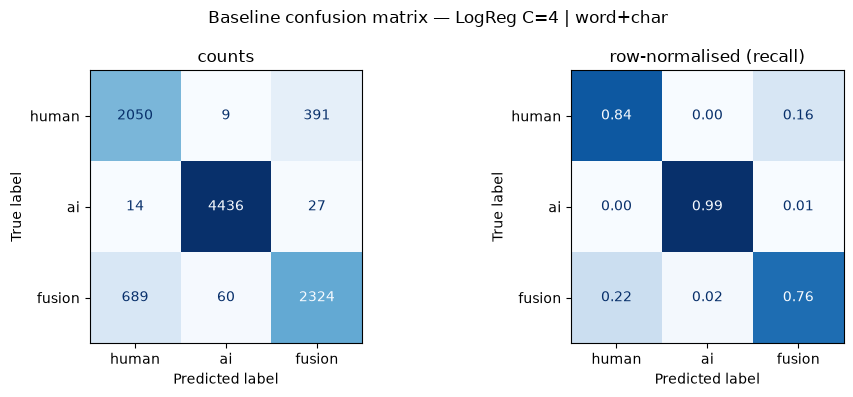

In [9]:
pred_va = best.predict(F["va"])
print(f"BEST: {BEST_KEY} on {BEST_FEATS}   macro-F1 = {macro_f1(y_va, pred_va):.4f}\n")
print(classification_report(y_va, pred_va, labels=LABELS, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, title in [(axes[0], None, "counts"), (axes[1], "true", "row-normalised (recall)")]:
    cm = confusion_matrix(y_va, pred_va, labels=LABELS, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False,
                                                           values_format=".2f" if norm else "d")
    ax.set_title(title)
fig.suptitle(f"Baseline confusion matrix — {BEST_KEY} | {BEST_FEATS}")
plt.tight_layout(); plt.show()

In [10]:
ev = val_df[["domain", "lang"]].assign(y=y_va, pred=pred_va)
rows = [{"group": col, "value": v, "n": len(g), "macro_f1": macro_f1(g.y, g.pred), "acc": (g.y == g.pred).mean()}
        for col in ("domain", "lang") for v, g in ev.groupby(col)]
print(pd.DataFrame(rows).sort_values(["group", "macro_f1"]).round(3).to_string(index=False))

 group                  value    n  macro_f1   acc
domain              gutenberg  270     0.559 0.937
domain           arxiv_papers  524     0.650 0.937
domain blog_authorship_corpus 1489     0.769 0.786
domain       euro_court_cases 1012     0.831 0.854
domain       house_of_commons 1170     0.867 0.895
domain              bundestag 1922     0.881 0.889
domain               cnn_news 1627     0.887 0.907
domain         student_essays 1986     0.895 0.906
  lang                  en-EN 8061     0.852 0.879
  lang                  de-DE 1939     0.881 0.890


## 5. What the linear model relies on (top n-grams per class)

Look for artifacts (prompt leaks such as `Output Text`, redaction patterns, quote or dash style) versus genuine style
words. Artifacts are worth a sentence in the report and are a natural starting point for the xAI bonus.

In [11]:
blocks, start = [], 0
for v in F["vecs"]:
    n = len(v.vocabulary_)
    blocks.append((v.analyzer, v.get_feature_names_out(), slice(start, start + n)))
    start += n
W = best.coef_ if hasattr(best, "coef_") else best.feature_log_prob_ - best.feature_log_prob_.mean(axis=0)
for cls, w in zip(best.classes_, W):
    for analyzer, names, sl in blocks:
        top = np.argsort(w[sl])[-12:][::-1]
        print(f"[{cls}] {analyzer:7s}: {', '.join(repr(names[i]) for i in top)}")

[ai] word   : '"', '?', '!', '’', '’ s', ', I', '. “', '’ t', '”', '*', '—', ', a'
[ai] char_wb: '’s ', 't? ', 'e! ', 's! ', ' – ', 't’s ', 't’s', 'n’t ', '’t ', 'n’t', ' , ', 'n? '
[fusion] word   : '. …', '…', '. .', '. and', 'me know', 'Let me', 'know if', "'", 'We must', '. –', '. This', 'and'
[fusion] char_wb: " ' ", ' " ', ' ...', ' ..', ' ’ ', ' U. ', 'U. ', ' S. ', ' S.', ' . ', ' ...a', ' … '
[human] word   : 'Dank .', 'Dank', 'of the', 'to the', '. Vielen', 'for the', 'urlLink', 'CNN', ', und', 'Vielen', 'is', 'Vielen Dank'
[human] char_wb: ".' ", '.’ ', '." ', '.S.', 'U.S.', 'U.S', ' U.S.', ' U.S', '.S. ', 'U.S. ', "e.'", "s.' "


## 6. Test predictions, saved scores, results log

In [12]:
scores_va = best.predict_proba(F["va"]) if hasattr(best, "predict_proba") else best.decision_function(F["va"])
save_val_scores("01_tfidf_best", val_df.id, scores_va, best.classes_)

F.pop("tr"); gc.collect()                       # training matrix no longer needed
X_te = hstack_csr([v.transform(txt_te) for v in F["vecs"]])
pred_te = best.predict(X_te)
tag = BEST_KEY.replace(" ", "_").replace("=", "")
save_submission(test_df.id, pred_te, f"01_tfidf_{BEST_FEATS.replace('+', '_')}_{tag}")

saved submissions/01_tfidf_word_char_LogReg_C4.csv  rows=25000  label share={'ai': 0.516, 'human': 0.272, 'fusion': 0.212}


In [13]:
results = pd.read_csv(OUTPUT_DIR / "results.csv")
print(results[results.experiment == "01_baseline"]
      .sort_values("macro_f1", ascending=False)
      .drop(columns=["time", "experiment"]).head(12).to_string(index=False))

                                          model  macro_f1  f1_human  f1_ai  f1_fusion                 notes
         LogReg C=4 no class_weight | word+char    0.8601    0.7875 0.9877     0.8052 class weight ablation
                         LogReg C=4 | word+char    0.8584    0.7880 0.9878     0.7993      parameter search
                        LogReg C=16 | word+char    0.8556    0.7816 0.9867     0.7986      parameter search
                         LogReg C=1 | word+char    0.8554    0.7881 0.9867     0.7913      parameter search
                   SGD-hinge a=3e-5 | word+char    0.8480    0.7755 0.9841     0.7843   vectorizer ablation
 SGD_hinge (linear SVM) alpha=3e-05 | word+char    0.8480    0.7755 0.9841     0.7843      parameter search
          SGD_modhuber alpha=0.0001 | word+char    0.8459    0.7721 0.9847     0.7810      parameter search
           SGD_modhuber alpha=3e-05 | word+char    0.8453    0.7628 0.9847     0.7886      parameter search
 SGD_hinge (linear SVM) alph